# Forecasting

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [3]:
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

In [4]:
from src.experiments.artifacts import ReconstructedStore

store = ReconstructedStore(OUTPUTS / "reconstructed")

In [5]:
import pandas as pd
import numpy as np

Repeat code from `imputation.ipynb`.

In [6]:
from src.data import load_ett, chronological_split, scale

train, test = chronological_split(load_ett())
train_s, test_s, scaler = scale(train=train, test=test)

Set horizon length.

In [7]:
H = 24 * 7

In [8]:
truth = test_s["OT"].iloc[:H].to_numpy()

## Baseline Forecast with Original Complete Data

**Exponential Smoothing**

In [8]:
from src.forecasters.exp_smoothing import ExpSmoothingForecaster

exp_base = ExpSmoothingForecaster(seasonal_periods=24, seasonal="add", trend="add", damped_trend=True)
exp_base.fit(train_s)
exp_base_forecast = exp_base.predict(horizon=H)

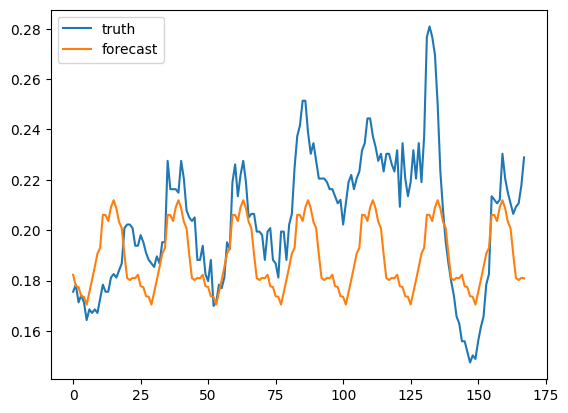

In [9]:
import matplotlib.pyplot as plt

plt.plot(truth, label="truth")
plt.plot(exp_base_forecast, label="forecast")
plt.legend()
plt.show()

In [10]:
np.sqrt(np.mean((exp_base_forecast - truth)**2))

np.float64(0.027124516363653085)

**XGBoost**

In [10]:
from src.forecasters.xgb import XGBoostForecaster

xgb_base = XGBoostForecaster(lags=[1, 24, 168])
xgb_base_trained = xgb_base.fit(train_s)
xgb_base_forecast = xgb_base_trained.predict(horizon=H)

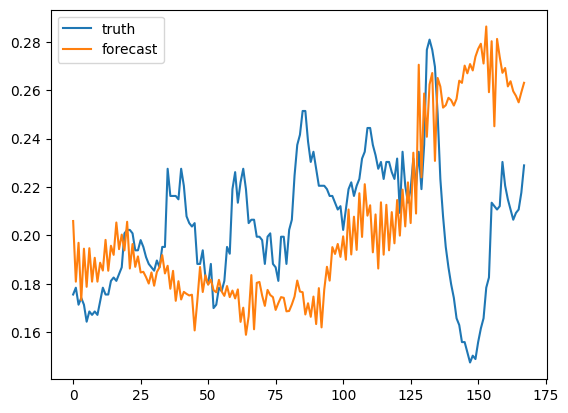

In [11]:
import matplotlib.pyplot as plt

plt.plot(truth, label="truth")
plt.plot(xgb_base_forecast, label="forecast")
plt.legend()
plt.show()

In [12]:
np.sqrt(np.mean((xgb_base_forecast - truth) ** 2))

np.float64(0.044807582796475225)

## Forecasting Experiment

Extract OT scaler, and prepare unscaling function.

In [13]:
from src.forecasters.base import TARGET

ot_i = list(train.columns).index(TARGET)
ot_min, ot_max = scaler.data_min_[ot_i], scaler.data_max_[ot_i]

def unscale_ot(x):
    """Inverse-transform a scaled OT array/series back to raw units."""
    return x * (ot_max - ot_min) + ot_min

Unscale truth and baseline model outputs.

In [14]:
from src.experiments.forecasting import ForecastingExperiment
from src.forecasters import FORECASTERS

truth_raw = unscale_ot(truth)

baselines = {
    "exp_smoothing": unscale_ot(exp_base_forecast),
    "xgboost": unscale_ot(xgb_base_forecast),
}

c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initiate experiment.

In [15]:
experiment = ForecastingExperiment(forecasters=list(FORECASTERS))
bv_df = experiment.run(horizon=H, store=store, truth=truth, baselines=baselines, unscale_fn = unscale_ot)

forecasting:   0%|          | 0/450 [00:00<?, ?it/s]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
forecasting:   0%|          | 1/450 [00:03<27:45,  3.71s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
forecasting:   0%|          | 2/450 [00:07<27:30,  3.68s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
forecasting:   1%|          | 3/450 [00:11<27:29,  3.69s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\tsa\ba

Save bias-variance data output.

In [16]:
bv_df.to_parquet(OUTPUTS / "bias_variance.parquet")

In [17]:
bv_df

,mechanism,proportion,imputer,forecaster,bias_vs_truth,bias_vs_baseline,variance
0,mar,10,arima,xgboost,83.406760,11.492931,9.363059
1,mar,10,arima,exp_smoothing,26.929200,0.002515,0.005897
2,mar,10,brits,xgboost,70.984081,6.721563,23.694686
3,mar,10,brits,exp_smoothing,28.935509,0.037466,0.019273
4,mar,10,ks,xgboost,53.774945,3.010762,10.141844
...,...,...,...,...,...,...,...
85,mnar,50,ks,exp_smoothing,28.593149,0.042737,0.000758
86,mnar,50,locf,xgboost,42.452891,1.996680,3.776329
87,mnar,50,locf,exp_smoothing,26.651523,0.064951,0.002117
88,mnar,50,mean,xgboost,96.637256,18.006606,16.692698


## Results

In [6]:
bv_df = pd.read_parquet(OUTPUTS / "bias_variance.parquet")

In [10]:
bv_df[(bv_df["mechanism"] == "mcar") & (bv_df["proportion"] == 30) & (bv_df["forecaster"] == "xgboost")]

,mechanism,proportion,imputer,forecaster,bias_vs_truth,bias_vs_baseline,variance
40,mcar,30,arima,xgboost,29.626694,4.857324,2.821089
42,mcar,30,brits,xgboost,46.150397,0.972759,8.643686
44,mcar,30,ks,xgboost,58.463608,1.325427,9.815597
46,mcar,30,locf,xgboost,85.349248,6.038026,7.552531
48,mcar,30,mean,xgboost,202.851599,57.046636,6.863648


In [11]:
bv_df.groupby("proportion")[["bias_vs_baseline","variance"]].mean()

,bias_vs_baseline,variance
proportion,,
10,5.359314,5.596669
30,7.153593,5.339731
50,8.699748,4.607984


In [12]:
bv_df.groupby("forecaster")[["bias_vs_baseline","variance"]].mean()

,bias_vs_baseline,variance
forecaster,,
exp_smoothing,2.342778,0.420449
xgboost,11.798993,9.942473


In [13]:
bv_df.groupby("imputer")[["bias_vs_baseline","variance"]].mean().sort_values("bias_vs_baseline")

,bias_vs_baseline,variance
imputer,,
locf,1.207138,4.401296
arima,1.279107,3.048178
ks,1.828237,3.720330
brits,1.960253,6.618508
mean,29.079690,8.118993


In [14]:
bv_df.groupby("mechanism")[["bias_vs_baseline","variance"]].mean()

,bias_vs_baseline,variance
mechanism,,
mar,10.505276,6.411063
mcar,7.888604,3.879349
mnar,2.818776,5.253971


In [15]:
bv_df[bv_df.forecaster=="xgboost"].pivot_table("bias_vs_baseline", "imputer", "proportion")

proportion,10,30,50
imputer,,,
arima,3.020555,2.162439,2.446009
brits,2.149340,3.084915,3.134626
ks,1.789011,3.339548,5.673063
locf,1.054997,3.184191,2.854738
mean,44.471977,48.597936,50.021544


In [16]:
bv_df[["bias_vs_truth","bias_vs_baseline"]].mean()

bias_vs_truth       56.871178
bias_vs_baseline     7.070885
dtype: float64

In [17]:
bv_df.groupby(["forecaster","mechanism"])["bias_vs_baseline"].mean()

forecaster     mechanism
exp_smoothing  mar           5.129612
               mcar          1.785231
               mnar          0.113490
xgboost        mar          15.880940
               mcar         13.991976
               mnar          5.524061
Name: bias_vs_baseline, dtype: float64

In [18]:
# std of reconstructed OT per mechanism, one proportion
from src.experiments.artifacts import OriginKey

for mech in ["mar","mcar","mnar"]:
    s = store.get(OriginKey(mech, 50, 0, "ks"))["OT"].std()
    print(mech, round(s,4))

mar 0.1657
mcar 0.1664
mnar 0.1652


In [19]:
for mech in ["mar","mcar","mnar"]:
    s = store.get(OriginKey(mech, 50, 0, "ks"))["OT"].iloc[-168:].std()
    print(mech, round(s,4))

mar 0.0512
mcar 0.0521
mnar 0.054
